# Part 1, extension 1: what is the network looking at?

The deforestation detector from notebook 02 says "lost" or "stable" for each 640 m patch. This notebook shows **which parts of each patch drove that answer**, as a heatmap laid over the satellite images. The method is Grad-CAM (Selvaraju et al. 2017). It follows the network's own signal back to the patch and asks which areas pushed the score towards "lost".

Heatmaps can look convincing even when they are meaningless, so nothing is shown until it passes four checks:

1. **Same model, same data.** The saved model must reproduce the exact test predictions saved by notebook 02.
2. **Sanity test.** The heatmaps of a randomly initialised network (same design, no learning) must look different from the trained one (Adebayo et al. 2018).
3. **Faithfulness.** Hiding the hottest pixels must lower the "lost" score more than hiding the same number of random pixels.
4. **Ground truth.** The hottest pixels should fall on the pixels that Hansen's map says actually lost forest, more often than chance.

Only the test patches are used, so everything here is about places the network never trained on.

## 1. Setup

In [1]:
import os
import json
import time
import random
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet18
from sklearn.metrics import balanced_accuracy_score
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# Must match notebook 02 exactly, so the split and scaling come out the same
PATCH_DIR = "../data/raw/part1_patches"
INDEX_CSV = "../data/cleaned/part1_patch_index.csv"
OUT_DIR = "../outputs"
MODEL_PATH = "../models/part1_resnet18.pt"
PRED_CSV = "../outputs/part1_test_predictions.csv"
SEED = 42
SPLIT = (0.70, 0.15, 0.15)
BANDS = ["B2", "B3", "B4", "B8", "B11", "B12"]
CHANNELS = [f"{b}_{t}" for t in ("before", "after") for b in BANDS]

# Settings for this notebook
TOP_SHARE = 0.10            # "hottest pixels" = the top 10% of each heatmap
EE_PROJECT = "earth-01-final"
PATCH_PX, PIXEL_M = 64, 10  # as in notebook 01
MASK_CACHE = "../data/raw/part1_hansen_masks"   # Hansen lost-pixel masks for the test patches

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(SEED)
device = torch.device("mps" if torch.backends.mps.is_available()
                      else "cuda" if torch.cuda.is_available() else "cpu")
print("Running on", device)

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Running on mps


## 2. Rebuild the exact test set from notebook 02

The code in the next three cells is copied unchanged from notebook 02.

In [2]:
index = pd.read_csv(INDEX_CSV)

Xs, ys, ids = [], [], []
for fname in sorted(os.listdir(PATCH_DIR)):
    if fname.endswith(".npz"):
        z = np.load(os.path.join(PATCH_DIR, fname), allow_pickle=True)
        Xs.append(z["X"]); ys.append(z["y"]); ids.extend(z["patch_id"].tolist())
X = np.concatenate(Xs)                      # (patches, 12, 64, 64), whole numbers (uint16)
meta = index.set_index("patch_id").loc[ids].reset_index()
y = meta["label"].to_numpy(np.int64)        # 0 = stable forest, 1 = forest lost

assert len(X) == len(meta) == len(index), "the .npz files and the index CSV disagree; rerun step 1 sections 7"
assert (np.concatenate(ys) == y).all(), "labels in the .npz files and the index CSV disagree"
assert meta["patch_id"].is_unique
print(f"{len(X)} patches, {X.shape[1]} bands of {X.shape[2]}x{X.shape[3]} pixels")
print(meta.groupby(["country", "label"]).size().unstack().rename(columns={0: "stable", 1: "lost"}))

6292 patches, 12 bands of 64x64 pixels
label                             stable  lost
country                                       
Brazil                              1000  1000
Democratic Republic of the Congo    1000   516
India                                455   473
Indonesia                            946   902


In [3]:
def split_blocks(meta, fractions, seed):
    rng = np.random.default_rng(seed)
    part = pd.Series("", index=meta.index)
    for country, g in meta.groupby("country"):
        blocks = g["block"].unique()
        rng.shuffle(blocks)
        share = g.groupby("block").size().loc[blocks].cumsum() / len(g)   # running share of patches
        names = np.where(share <= fractions[0], "train",
                         np.where(share <= fractions[0] + fractions[1], "val", "test"))
        part.loc[g.index] = g["block"].map(dict(zip(blocks, names)))
    return part

n_countries = meta["country"].nunique()
for attempt in range(200):
    meta["split"] = split_blocks(meta, SPLIT, SEED + attempt)
    classes = meta.groupby(["country", "split"])["label"].nunique()
    if len(classes) == n_countries * 3 and (classes == 2).all():
        break
else:
    raise RuntimeError("could not find a block split with both classes everywhere; lower the test share")

assert meta.groupby("block")["split"].nunique().max() == 1, "a block ended up in two groups"
tr = np.where(meta["split"] == "train")[0]
va = np.where(meta["split"] == "val")[0]
te = np.where(meta["split"] == "test")[0]
print(f"Split found on attempt {attempt + 1}: {len(tr)} train, {len(va)} validation, {len(te)} test")
print(meta.groupby(["country", "split", "label"]).size().unstack().rename(columns={0: "stable", 1: "lost"}))

Split found on attempt 1: 4312 train, 930 validation, 1050 test
label                                   stable  lost
country                          split              
Brazil                           test      151   154
                                 train     690   701
                                 val       159   145
Democratic Republic of the Congo test      183    62
                                 train     648   383
                                 val       169    71
India                            test       98    84
                                 train     290   327
                                 val        67    62
Indonesia                        test      158   160
                                 train     668   605
                                 val       120   137


/var/folders/b9/6zcj3lks1sj71xf32vysyr8h0000gn/T/ipykernel_7451/2938831922.py:6: UserWarning: you are shuffling a 'ArrowStringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  rng.shuffle(blocks)
/var/folders/b9/6zcj3lks1sj71xf32vysyr8h0000gn/T/ipykernel_7451/2938831922.py:6: UserWarning: you are shuffling a 'ArrowStringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicates after shuffling.
  rng.shuffle(blocks)
/var/folders/b9/6zcj3lks1sj71xf32vysyr8h0000gn/T/ipykernel_7451/2938831922.py:6: UserWarning: you are shuffling a 'ArrowStringArray' object which is not a subclass of 'Sequence'; `shuffle` is not guaranteed to behave correctly. E.g., non-numpy array/tensor objects with view semantics may contain duplicate

In [4]:
mean = np.array([X[tr, c].astype(np.float32).mean() for c in range(X.shape[1])], dtype=np.float32)
std = np.array([X[tr, c].astype(np.float32).std() for c in range(X.shape[1])], dtype=np.float32)
MEAN = torch.tensor(mean).view(1, -1, 1, 1).to(device)
STD = torch.tensor(std).view(1, -1, 1, 1).to(device)

def to_batch(idx, augment=False):
    xb = torch.from_numpy(X[idx].astype(np.float32)).to(device)
    xb = (xb - MEAN) / STD
    if augment:
        xb = torch.stack([torch.rot90(x, random.randint(0, 3), dims=(1, 2)) for x in xb])
        flip = torch.rand(len(xb), device=device) < 0.5
        xb[flip] = torch.flip(xb[flip], dims=(3,))
    return xb, torch.from_numpy(y[idx]).to(device)

print(pd.DataFrame({"mean": mean, "std": std}, index=CHANNELS).round(0))

              mean    std
B2_before    972.0  104.0
B3_before    836.0  102.0
B4_before    548.0  114.0
B8_before   2613.0  416.0
B11_before  1408.0  247.0
B12_before   559.0  143.0
B2_after    1011.0  111.0
B3_after     882.0  121.0
B4_after     602.0  159.0
B8_after    2649.0  439.0
B11_after   1535.0  377.0
B12_after    637.0  246.0


## 3. Check 1: the saved model reproduces notebook 02's test results

If this check fails, stop here. It would mean the model file, the data or the split no longer match what was reported, and every heatmap below would be untrustworthy.

In [5]:
def build_model():
    model = resnet18(weights=None)                   # weights come from our saved file below
    old = model.conv1.weight.data                    # (64, 3, 7, 7), filters for red, green, blue
    rgb_for = {0: 2, 1: 1, 2: 0}                     # our B2 = blue, B3 = green, B4 = red
    new = torch.empty(64, len(CHANNELS), 7, 7)
    for c in range(len(CHANNELS)):
        b = c % len(BANDS)
        new[:, c] = old[:, rgb_for[b]] if b in rgb_for else old.mean(dim=1)
    model.conv1 = nn.Conv2d(len(CHANNELS), 64, kernel_size=7, stride=2, padding=3, bias=False)
    model.conv1.weight.data = new * 3 / len(CHANNELS)   # keep the layer's output at the same scale
    model.maxpool = nn.Identity()                    # 64x64 patches are small: skip one shrinking step
    model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.fc.in_features, 2))
    return model

model = build_model().to(device)
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))   # strict: every layer must match
model.eval()

@torch.no_grad()
def predict(net, idx):
    net.eval()
    probs = []
    for s in range(0, len(idx), 256):
        xb, _ = to_batch(idx[s:s + 256])
        probs.append(F.softmax(net(xb), dim=1)[:, 1].cpu())
    return torch.cat(probs).numpy()

saved = pd.read_csv(PRED_CSV)
assert set(saved["patch_id"]) == set(meta["patch_id"].iloc[te]), \
    "the test patches differ from notebook 02's; the split did not come out the same"
saved = saved.set_index("patch_id").loc[meta["patch_id"].iloc[te]]
p_now = predict(model, te)
gap = np.abs(p_now - saved["prob_lost"].to_numpy())
agree = ((p_now > 0.5).astype(int) == saved["predicted"].to_numpy()).mean()
print(f"Largest difference from the saved probabilities: {gap.max():.4f}")
print(f"Same lost/stable call as notebook 02 on {agree:.1%} of {len(te)} test patches")
print(f"Balanced accuracy now {balanced_accuracy_score(y[te], p_now > 0.5):.3f}")
assert gap.max() < 0.01 and agree >= 0.999, "the model does not reproduce notebook 02's results; stop here"
print("Check 1 passed")

Largest difference from the saved probabilities: 0.0000
Same lost/stable call as notebook 02 on 100.0% of 1050 test patches
Balanced accuracy now 0.938
Check 1 passed


## 4. Heatmaps (Grad-CAM)

Grad-CAM reads the network's middle layer (`layer3`), which sees the patch as an 8 × 8 grid of about 80 m cells. It weights each feature by how much it raised the "lost" score, then stretches the result back to 64 × 64 pixels. So the heatmaps show roughly where the network looked, about 80 m at a time, not individual 10 m pixels.

In [6]:
TARGET_LAYER = "layer3"

def gradcam(net, idx, layer_name=TARGET_LAYER, batch=64):
    layer = getattr(net, layer_name)
    net.eval()
    heat = []
    for s in range(0, len(idx), batch):
        store = {}
        def keep(module, inputs, output):
            store["act"] = output
            output.register_hook(lambda g: store.__setitem__("grad", g))
        handle = layer.register_forward_hook(keep)
        xb, _ = to_batch(idx[s:s + batch])
        xb.requires_grad_(False)
        net.zero_grad()
        logits = net(xb)
        logits[:, 1].sum().backward()          # explain the "lost" score
        handle.remove()
        act, grad = store["act"].detach(), store["grad"].detach()
        weights = grad.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * act).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=xb.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
        cam = cam / (cam.flatten(1).amax(dim=1).view(-1, 1, 1) + 1e-8)   # 0 to 1 per patch
        heat.append(cam.cpu().numpy())
    return np.concatenate(heat)

heat = gradcam(model, te)
assert heat.shape == (len(te), X.shape[2], X.shape[3]) and np.isfinite(heat).all()
caught = np.where((y[te] == 1) & (p_now > 0.5))[0]     # lost patches the network caught (positions in the test set)
print(f"Heatmaps for {len(heat)} test patches. {np.mean(heat[caught].max(axis=(1, 2)) > 0):.1%} of the "
      f"{len(caught)} caught lost patches have a heat signal (stable patches can rightly have none)")

Heatmaps for 1050 test patches. 100.0% of the 415 caught lost patches have a heat signal (stable patches can rightly have none)


## 5. Check 2: sanity test against an untrained network

A network with the same design but random weights has learned nothing. If its heatmaps looked like the trained ones, the heatmaps would just be showing image edges, not the model's reasoning. We compare the two with a rank correlation for each patch. Low means good.

In [7]:
from scipy.stats import spearmanr

set_seed(SEED)
random_net = build_model().to(device)    # same design, untrained weights
random_net.eval()
heat_random = gradcam(random_net, te)

def rank_corr(a, b):
    out = []
    for h1, h2 in zip(a, b):
        if h1.std() == 0 or h2.std() == 0:
            out.append(0.0)
        else:
            out.append(spearmanr(h1.ravel(), h2.ravel())[0])
    return np.array(out)

corr = rank_corr(heat[caught], heat_random[caught])     # on the caught lost patches
print(f"Rank correlation, trained vs untrained heatmaps on caught lost patches: median {np.median(corr):.2f} "
      f"(1 = identical, 0 = unrelated)")
sanity_ok = np.median(corr) < 0.5 and np.mean(heat[caught].max(axis=(1, 2)) > 0) > 0.9
print("Check 2 passed" if sanity_ok else "Check 2 FAILED: heatmaps may reflect image structure, not learning")

Rank correlation, trained vs untrained heatmaps on caught lost patches: median -0.03 (1 = identical, 0 = unrelated)
Check 2 passed


## 6. Check 3: faithfulness

For every lost patch the network caught, we hide the hottest 10% of pixels by setting them to the patch's own average. Then we see how far the network's "lost" margin drops (its raw score for lost minus its score for stable, which doesn't saturate near 100% the way a probability does). We do the same with 10% of pixels picked at random. If the heatmap is faithful, hiding the hot pixels should hurt much more.

In [8]:
@torch.no_grad()
def margin_with_hidden(idx, masks):
    out = []
    for s in range(0, len(idx), 128):
        xb, _ = to_batch(idx[s:s + 128])
        m = torch.from_numpy(masks[s:s + 128]).to(device).unsqueeze(1)         # 1 = hide
        fill = xb.mean(dim=(2, 3), keepdim=True)
        xb = torch.where(m, fill.expand_as(xb), xb)
        logits = model(xb)
        out.append((logits[:, 1] - logits[:, 0]).cpu())
    return torch.cat(out).numpy()

k = int(TOP_SHARE * heat.shape[1] * heat.shape[2])
top_masks = np.zeros(heat[caught].shape, dtype=bool)
rand_masks = np.zeros_like(top_masks)
rng = np.random.default_rng(SEED)
for i, h in enumerate(heat[caught]):
    top_masks[i].flat[np.argsort(h.ravel())[-k:]] = True
    rand_masks[i].flat[rng.choice(h.size, k, replace=False)] = True

m_base = margin_with_hidden(te[caught], np.zeros_like(top_masks))
drop_top = m_base - margin_with_hidden(te[caught], top_masks)
drop_rand = m_base - margin_with_hidden(te[caught], rand_masks)
print(f"{len(caught)} caught lost patches. Average drop in the 'lost' margin when hiding:")
print(f"  hottest 10% of pixels: {drop_top.mean():.3f}")
print(f"  random 10% of pixels:  {drop_rand.mean():.3f}")
print(f"  hiding the hottest pixels hurt more in {np.mean(drop_top > drop_rand):.1%} of patches")
# Pass only on a clear gap, not a tie: bigger average drop AND bigger in most patches
faithful_ok = (drop_top.mean() - drop_rand.mean() > 0.1) and np.mean(drop_top > drop_rand) > 0.5
print("Check 3 passed" if faithful_ok else "Check 3 FAILED or unclear: the heatmaps may not point at what the model uses")

415 caught lost patches. Average drop in the 'lost' margin when hiding:
  hottest 10% of pixels: 2.291
  random 10% of pixels:  1.168
  hiding the hottest pixels hurt more in 65.8% of patches
Check 3 passed


## 7. Check 4: do the hot spots sit on real forest loss?

Here we download Hansen's map of which 30 m pixels lost forest in 2019–2022 for each lost test patch. We use exactly the same rule and the same 64 × 64 grid as notebook 01, so each heatmap pixel lines up with a Hansen pixel. This needs a small amount of Earth Engine time (well under an hour), and the masks are cached so a rerun is free.

Two built-in checks on the downloaded masks themselves:
- each patch's share of lost pixels should match the `lost_frac` that notebook 01 recorded for it, and
- lost patches were chosen with at least 10% loss, so almost all should show that.

In [9]:
import ee
from pyproj import Transformer

ee.Authenticate()
ee.Initialize(project=EE_PROJECT, opt_url="https://earthengine-highvolume.googleapis.com")
ee.data.setDeadline(180_000)

# Same rule as notebook 01, section 3
hansen = ee.Image("UMD/hansen/global_forest_change_2023_v1_11")
treecover = hansen.select("treecover2000").unmask(0)
lossyear = hansen.select("lossyear").unmask(0)
land = hansen.select("datamask").eq(1)
forest2000 = treecover.gte(30).And(land)
lost_window = forest2000.And(lossyear.gte(19)).And(lossyear.lte(22)).rename("lost").toUint8()

# Same grid as notebook 01, section 6
half_m = PATCH_PX * PIXEL_M / 2
to_merc = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)
os.makedirs(MASK_CACHE, exist_ok=True)

def fetch_mask(row, retries=5):
    path = os.path.join(MASK_CACHE, f"{row.lat:.5f}_{row.lon:.5f}.npy")
    if os.path.exists(path):
        return row.patch_id, np.load(path)
    x, y_ = to_merc.transform(row.lon, row.lat)
    stretch = 1 / np.cos(np.radians(row.lat))
    px, half = PIXEL_M * stretch, half_m * stretch
    request = {
        "expression": lost_window,
        "fileFormat": "NUMPY_NDARRAY",
        "grid": {
            "dimensions": {"width": PATCH_PX, "height": PATCH_PX},
            "affineTransform": {"scaleX": px, "shearX": 0, "translateX": x - half,
                                "shearY": 0, "scaleY": -px, "translateY": y_ + half},
            "crsCode": "EPSG:3857",
        },
    }
    for attempt in range(retries):
        try:
            arr = ee.data.computePixels(request)
            out = np.asarray(arr["lost"], dtype=np.uint8)
            np.save(path, out)
            return row.patch_id, out
        except Exception as err:
            if attempt == retries - 1:
                print(f"{row.patch_id} failed: {str(err)[:120]}")
                return row.patch_id, None
            time.sleep(2 ** attempt)

lost_rows = meta.iloc[te][meta.iloc[te]["label"] == 1]
hansen_masks = {}
with ThreadPoolExecutor(max_workers=8) as pool:
    jobs = [pool.submit(fetch_mask, r) for r in lost_rows.itertuples()]
    for job in tqdm(as_completed(jobs), total=len(jobs)):
        pid, m = job.result()
        if m is not None:
            hansen_masks[pid] = m
print(f"Hansen masks for {len(hansen_masks)} of {len(lost_rows)} lost test patches")

/opt/anaconda3/lib/python3.13/site-packages/google/api_core/_python_package_support.py:206: FutureWarning: Package google.api_core depends on grpcio, currently installed at version 1.75.1. grpcio < 1.83.0 does not support Post-Quantum Cryptography (PQC). Support for non-PQC environments is deprecated. In April 2027, Google Cloud Python packages will raise their minimum requirements (including google-api-core, grpcio, and grpcio-status) to enforce grpcio >= 1.83.0. For more details on Google Cloud's post-quantum security migration, visit: https://cloud.google.com/security/resources/post-quantum-cryptography
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for UMD/hansen/global_forest_change_2023_v1_11! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by UMD/hansen/global_forest_change_2025_v1_13

Learn more: https://developers.google.com/e

  0%|          | 0/460 [00:00<?, ?it/s]

Hansen masks for 460 of 460 lost test patches


In [10]:
# Checks on the downloaded masks themselves
pid_te = meta["patch_id"].to_numpy()[te]
pos = {p: i for i, p in enumerate(pid_te)}
have = [p for p in lost_rows["patch_id"] if p in hansen_masks]
mask_share = np.array([hansen_masks[p].mean() for p in have])
recorded = lost_rows.set_index("patch_id").loc[have, "lost_frac"].to_numpy()
r = np.corrcoef(mask_share, recorded)[0, 1]
print(f"Lost share in the masks vs notebook 01's lost_frac: correlation {r:.3f}, "
      f"median gap {np.median(np.abs(mask_share - recorded)):.3f}")
print(f"{np.mean(mask_share >= 0.08):.1%} of lost patches show at least 8% lost pixels "
      f"(chosen at 10% or more; small gaps come from square vs Mercator footprints)")
masks_ok = r > 0.8
assert masks_ok, "the Hansen masks do not match the labels; do not use Check 4"

# Check 4: share of the hottest pixels that are truly lost, against chance (the patch's lost share)
rows = []
for p in have:
    i = pos[p]
    h, m = heat[i], hansen_masks[p].astype(bool)
    top = h >= np.quantile(h, 1 - TOP_SHARE)
    rows.append({"patch_id": p, "country": meta.iloc[te[i]]["country"],
                 "caught": bool(p_now[i] > 0.5), "hit": m[top].mean(), "chance": m.mean()})
hits = pd.DataFrame(rows)
hits["lift"] = hits["hit"] / hits["chance"].clip(lower=1e-6)
summary4 = hits.groupby("country")[["hit", "chance"]].mean()
summary4.loc["All"] = hits[["hit", "chance"]].mean()
summary4["times_better_than_chance"] = summary4["hit"] / summary4["chance"]
print("Share of the hottest 10% of pixels that Hansen marks as lost, vs chance:")
print(summary4.round(3).to_string())
for flag, name in [(True, "caught"), (False, "missed")]:
    sub = hits[hits.caught == flag]
    if len(sub):
        print(f"{name} patches ({len(sub)}): {sub.hit.mean():.1%} of hottest pixels on lost pixels, chance {sub.chance.mean():.1%}")
truth_ok = summary4.loc["All", "hit"] > summary4.loc["All", "chance"]
print("Check 4 passed" if truth_ok else "Check 4 FAILED: hot spots are not on real loss more than chance")

Lost share in the masks vs notebook 01's lost_frac: correlation 0.999, median gap 0.007
100.0% of lost patches show at least 8% lost pixels (chosen at 10% or more; small gaps come from square vs Mercator footprints)
Share of the hottest 10% of pixels that Hansen marks as lost, vs chance:
                                    hit  chance  times_better_than_chance
country                                                                  
Brazil                            0.775   0.496                     1.564
Democratic Republic of the Congo  0.669   0.248                     2.702
India                             0.470   0.215                     2.186
Indonesia                         0.734   0.502                     1.462
All                               0.691   0.413                     1.672
caught patches (415): 72.4% of hottest pixels on lost pixels, chance 43.6%
missed patches (45): 39.0% of hottest pixels on lost pixels, chance 20.0%
Check 4 passed


## 8. Pictures for the website

Examples from the test areas only, picked at random with a fixed seed (not hand-picked), from each outcome. The rows show the 2018 image, the 2023 image, the heatmap over 2023, and Hansen's lost pixels outlined in white. The images are brightened for viewing only. The model sees the original numbers.

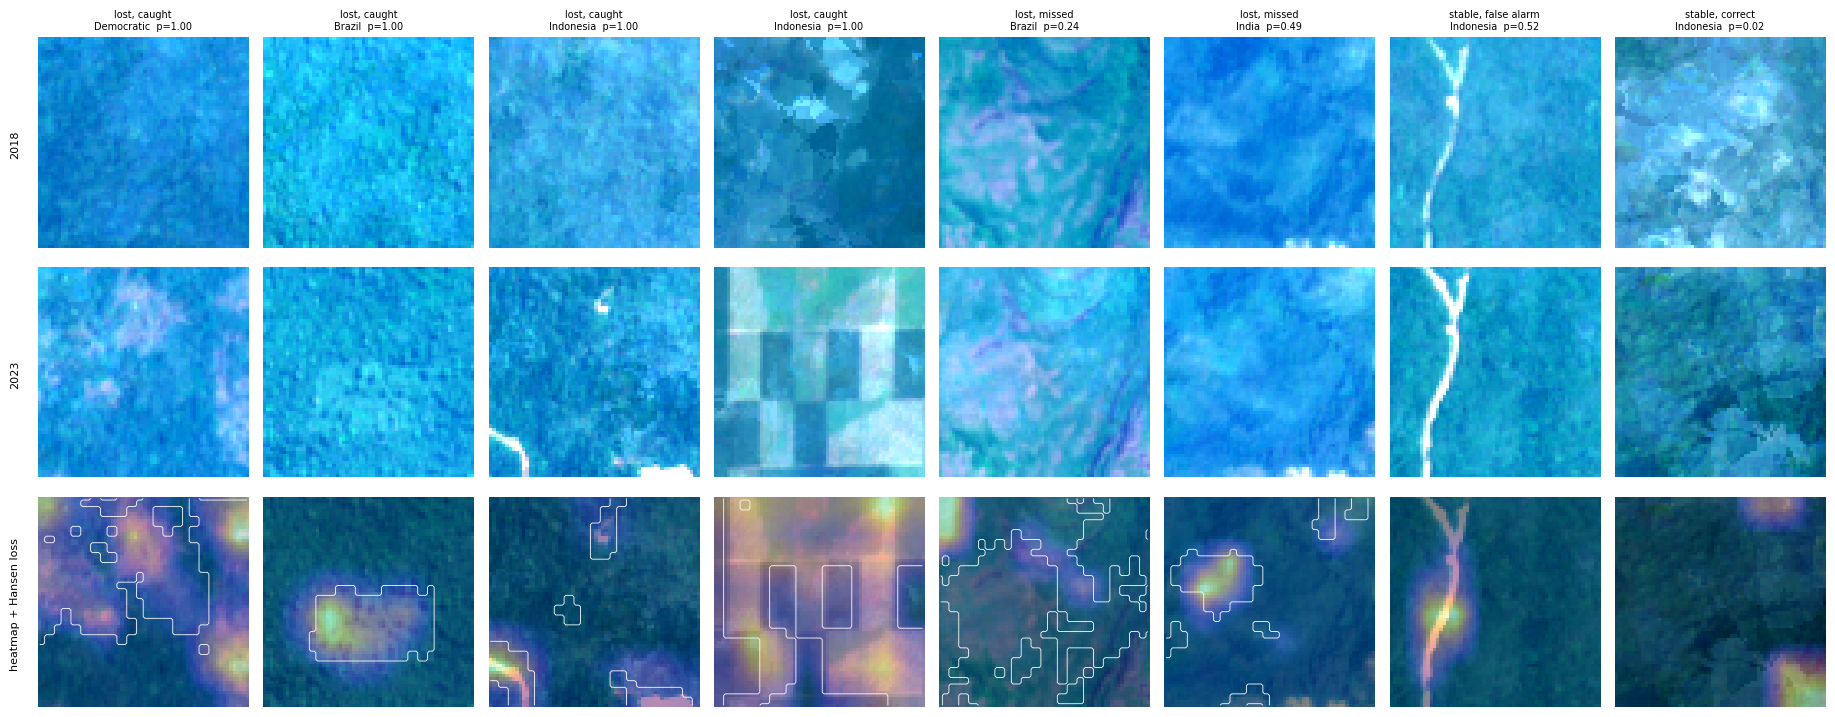

In [11]:
def rgb(arr, offset, lo, hi):
    img = arr[[offset + 2, offset + 1, offset]].transpose(1, 2, 0).astype(float)   # B4, B3, B2
    return np.clip((img - lo) / (hi - lo + 1e-6), 0, 1)

outcome = np.select([(y[te] == 1) & (p_now > 0.5), (y[te] == 1) & (p_now <= 0.5),
                     (y[te] == 0) & (p_now > 0.5)], ["lost, caught", "lost, missed", "stable, false alarm"],
                    "stable, correct")
plan = [("lost, caught", 4), ("lost, missed", 2), ("stable, false alarm", 1), ("stable, correct", 1)]
rng = np.random.default_rng(SEED)
picks = []
for name, n in plan:
    pool = np.where(outcome == name)[0]
    picks += [(name, i) for i in rng.choice(pool, min(n, len(pool)), replace=False)]

fig, axes = plt.subplots(3, len(picks), figsize=(2.3 * len(picks), 7.4), squeeze=False)
for col, (name, i) in enumerate(picks):
    arr = X[te[i]]
    vis = np.concatenate([arr[0:3].ravel(), arr[6:9].ravel()])
    lo, hi = np.percentile(vis, 2), np.percentile(vis, 98)          # same stretch for both years
    before, after = rgb(arr, 0, lo, hi), rgb(arr, 6, lo, hi)
    axes[0, col].imshow(before)
    axes[0, col].set_title(f"{name}\n{meta.iloc[te[i]]['country'][:10]}  p={p_now[i]:.2f}", fontsize=7)
    axes[1, col].imshow(after)
    axes[2, col].imshow(after)
    axes[2, col].imshow(heat[i], cmap="inferno", alpha=0.5, vmin=0, vmax=1)
    pid = pid_te[i]
    if pid in hansen_masks:
        axes[2, col].contour(hansen_masks[pid], levels=[0.5], colors="white", linewidths=0.6)
    for ax in axes[:, col]:
        ax.axis("off")
for row, text in enumerate(["2018", "2023", "heatmap + Hansen loss"]):
    axes[row, 0].text(-6, 32, text, rotation=90, va="center", ha="right", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "part1_gradcam_examples.png"), dpi=200)
plt.show()

In [12]:
checks = {
    "method": "Grad-CAM on layer3 (8x8 cells, about 80 m), explaining the 'lost' score",
    "test_patches": int(len(te)),
    "check1_reproduces_notebook02": {"max_prob_gap": float(gap.max()), "same_call_share": float(agree)},
    "check2_sanity_median_rank_corr_vs_untrained": float(np.median(corr)),
    "check3_faithfulness": {"patches": int(len(caught)), "mean_drop_hide_hottest": float(drop_top.mean()),
                            "mean_drop_hide_random": float(drop_rand.mean()),
                            "share_hottest_hurts_more": float(np.mean(drop_top > drop_rand))},
    "check4_hansen": {"mask_vs_label_corr": float(r),
                      "by_country": {c: {k: float(v) for k, v in row.items()} for c, row in summary4.iterrows()}},
    "passed": {"check2": bool(sanity_ok), "check3": bool(faithful_ok), "check4": bool(truth_ok)},
}
with open(os.path.join(OUT_DIR, "part1_gradcam_checks.json"), "w") as f:
    json.dump(checks, f, indent=2)
print(json.dumps(checks["passed"]), "saved to", os.path.join(OUT_DIR, "part1_gradcam_checks.json"))

{"check2": true, "check3": true, "check4": true} saved to ../outputs/part1_gradcam_checks.json


## 9. What the heatmaps do and don't show

- **Where, not why.** A heatmap shows which areas raised the "lost" score. It doesn't say what the network "thought" about them.
- **Coarse.** Each heatmap cell covers about 80 m, so thin roads or single trees can't be pinned down exactly.
- **One method.** Grad-CAM is one of several explanation methods, and they don't always agree. The checks above test whether this one is trustworthy for this model. They can't make it perfect.
- **Hansen isn't ground truth either.** Check 4 measures agreement with another satellite-based map, not with field surveys.

## Sources

- Selvaraju, R. R. et al. (2017), *Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization*, ICCV.
- Adebayo, J. et al. (2018), *Sanity Checks for Saliency Maps*, NeurIPS.
- Hansen, M. C. et al. (2013), Science 342, v1.11 (CC BY 4.0). Sentinel-2 imagery: contains modified Copernicus Sentinel data.